# S3 Day 1 — 定义任务 + 数据审计 + 线性基线

> **Section 3: Trustworthy Machine-Learning Baselines**（老师材料，`sections/s03/guide.md` & `homework.md`）
> 本 notebook 对应 **Day 1** 任务：定义任务、更新数据审计、一次 train/test split、dummy + linear 基线。
> Day 2（交叉验证/泄漏）和 Day 3（分类评估）在单独文件里，最后合并。

## Day 1 范围（Three-Day Map）
- Define the two tasks（定义回归 + 分类任务）
- Update the data audit（用建模用到的精确行审计）
- Make one train/test split（80/20, random_state=42）
- Fit dummy and linear models（dummy + LinearRegression baseline）

## 运行方式
从仓库根目录运行。**Restart Kernel and Run All** 应完整无错跑通。

## 0. 环境与加载（复用 S2 的加载代码）

我们**复用**你在 Section 2 的加载代码：定位仓库根目录、相对路径读 CSV、导入库。
和 S2 不同：S3 是**建模视角**，要把 `HOMO_LUMO_Gap_eV` 当作**目标**。

In [1]:
# Fix the working directory to the repository root so that all relative paths
# are computed from the repo root, regardless of which directory the kernel starts in.
import os
cwd = os.getcwd()
root = cwd
for _ in range(6):
    if os.path.isdir(os.path.join(root, "sections")):
        break
    parent = os.path.dirname(root)
    if parent == root:
        break
    root = parent
os.chdir(root)
print("Current cwd:", os.getcwd())

# 1. Import the libraries
import pandas as pd                  # tabular data handling
import numpy as np                   # numeric computation
import matplotlib.pyplot as plt      # plotting
import seaborn as sns                # nicer statistical plots
from sklearn.model_selection import train_test_split   # train/test split
from sklearn.pipeline import Pipeline                  # preprocessing + model
from sklearn.preprocessing import StandardScaler       # z-score standardization
from sklearn.linear_model import LinearRegression      # our regression model
from sklearn.dummy import DummyRegressor, DummyClassifier  # simple baselines
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # metrics

# 2. Load the CSV using a repository-relative path
df = pd.read_csv("sections/s02/homework/openpoly_calculated_properties.csv")
print("Data shape:", df.shape)   # (1000, 23): 1000 rows, 23 columns

Current cwd: /home/administrator/course


Data shape: (1000, 23)


## 1. 定义任务（Fixed Experiment Contract 第 1 步）

### 回归任务
- **目标（Y）**：`HOMO_LUMO_Gap_eV`（带隙），单位 **eV**
- **观察单位**：一行 = 一条计算聚合物记录
- **含义**：用其他计算属性预测带隙数值

### 分类任务
- **标签（Y）**：`high_gap`（1 = 高带隙，0 = 低带隙）
- 阈值：由**训练集**的带隙中位数决定（Day 1 先定义，Day 3 评估）

### 诚实特征（Honest predictors）
从 S2 的 13 个数值属性出发，**排除**：
- `id`（标识符）
- `HOMO_LUMO_Gap_eV`（目标是目标，不能当特征）
- `HOMO_eV`, `LUMO_eV`（两者相加 = 目标 → **泄漏**）

剩下 **10 个诚实特征**。

In [2]:
# --- 定义 13 个数值属性列（复用 S2） ---
property_cols = df.select_dtypes(include=["float64", "int64"]).columns.tolist()
property_cols.remove("id")
print("13 numeric property columns:", property_cols)

# --- 定义目标列 ---
target = "HOMO_LUMO_Gap_eV"

# --- 定义诚实特征：13 个减去 目标 + 泄漏的两列 ---
honest_feats = [c for c in property_cols
                if c != target and c not in ("HOMO_eV", "LUMO_eV")]
print(f"\n诚实特征数量: {len(honest_feats)}")
print("诚实特征:", honest_feats)

13 numeric property columns: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'HOMO_eV', 'LUMO_eV', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree', 'HOMO_LUMO_Gap_eV']

诚实特征数量: 10
诚实特征: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree']


## 2. 数据审计 + 清洗（建模用到的精确行）

老师 homework 要求：
- 把 `Energy_Hatree == 0` 的行视为**计算失败**，用代码排除
- **报告**移除多少行、保留多少行
- 联系 S2 的证据说明为什么（你 S2 里已经注意到 `Energy_Hatree==0` 是缺失占位）

In [3]:
# --- 有效性规则：排除 Energy_Hatree == 0 ---
raw_rows = len(df)
invalid_mask = df["Energy_Hatree"] == 0
removed = int(invalid_mask.sum())
valid = df[~invalid_mask].copy()
print(f"原始行数: {raw_rows}")
print(f"移除 (Energy_Hatree==0): {removed}")
print(f"保留 (valid): {len(valid)}")

# --- 展示有效行的目标分布 ---
print("\n目标 (HOMO_LUMO_Gap_eV) 在有效行上的描述统计：")
print(valid[target].describe())

原始行数: 1000
移除 (Energy_Hatree==0): 74
保留 (valid): 926

目标 (HOMO_LUMO_Gap_eV) 在有效行上的描述统计：
count    926.000000
mean       8.308145
std        0.481351
min        4.468900
25%        8.022225
50%        8.339550
75%        8.612650
max       10.001000
Name: HOMO_LUMO_Gap_eV, dtype: float64


### 清洗结果理解

> **说明（observation）**：原始 1000 行中，有 74 行的 `Energy_Hatree == 0`，排除后保留 926 个有效行。
>
> **解释（interpretation）**：这 74 行的能量为 0，是数据的**占位符/缺失值**（能量在物理上不可能是 0）。这部分数据是在 S2 里我们识别出来的"可能不合理/缺失"的数据，这里把它们正式过滤掉，作为建模用的精确行。这是老师 homework 规定的有效性规则（Fixed Experiment Contract）。
>
> **局限（limitation）**：排除标准是"`Energy_Hatree == 0`"。如果真实数据存在其他形式的缺失或异常值，这个规则并不能覆盖它们。是否还有其他需要过滤的行，需要进一步判断。

## 3. 切分数据 + 定义分类标签

### 3a. train/test split（80/20）
- 对 **926 个有效样本**做 80/20 切分
- `random_state=42` 保证**可复现**
- 只切分**索引**（保留原始行号），方便回归/分类共用同一套行

### 3b. 分类标签 `high_gap`
- 阈值 = **训练集**的带隙中位数（**只用训练集**算，测试集必须"干净"）
- `high_gap = 1` 当 gap ≥ 训练中位数，否则 0
- 这只是构造一个练习用分类任务，**不是**科学上验证过的物理分界

In [4]:
# ============ 切分数据（只切索引，回归/分类共用同一套行）============
valid_idx = valid.index.values                      # 926 个有效样本的原始行号
train_idx, test_idx = train_test_split(
    valid_idx,
    test_size=0.2,
    random_state=42,
)
# 排序，方便阅读（不影响结果）
train_idx = np.sort(train_idx)
test_idx  = np.sort(test_idx)

print(f"有效样本总数: {len(valid_idx)}")
print(f"训练集行数: {len(train_idx)}  ({(len(train_idx)/len(valid_idx))*100:.0f}%)")
print(f"测试集行数: {len(test_idx)} ({len(test_idx)/len(valid_idx)*100:.0f}%)")
print(f"训练/测试是否重叠: {len(set(train_idx) & set(test_idx))} 个重叠（应为0）")

有效样本总数: 926
训练集行数: 740  (80%)
测试集行数: 186 (20%)
训练/测试是否重叠: 0 个重叠（应为0）


In [5]:
# 用切分好的行号取数据集（特征 X 与目标 y 分开）
train = valid.loc[train_idx]
test  = valid.loc[test_idx]

X_train = train[honest_feats]   # 只用 10 个诚实特征
y_train = train[target]         # 回归目标（数值）

X_test  = test[honest_feats]
y_test  = test[target]

print("X_train shape:", X_train.shape)   # (约740, 10)
print("X_test shape :", X_test.shape)    # (约186, 10)

X_train shape: (740, 10)
X_test shape : (186, 10)


In [6]:
# ============ 分类标签：仅用训练集的带隙中位数做阈值 ============
train_median = y_train.median()      # 只用训练集！不碰测试集
print(f"训练集带隙中位数（分类阈值）: {train_median:.4f} eV")

# 构造高低标签
y_train_cls = (train[target] >= train_median).astype(int)  # high_gap = 1
y_test_cls  = (test[target]  >= train_median).astype(int)

print("\n训练集类别分布:")
print(y_train_cls.value_counts())
print("\n测试集类别分布:")
print(y_test_cls.value_counts())

训练集带隙中位数（分类阈值）: 8.3323 eV

训练集类别分布:
HOMO_LUMO_Gap_eV
1    370
0    370
Name: count, dtype: int64

测试集类别分布:
HOMO_LUMO_Gap_eV
1    102
0     84
Name: count, dtype: int64


### 切分与分类标签理解

> **为什么随机种子要固定？** 保证**可复现**。`random_state=42` 给"随机切分"一个固定起点，使每次运行都切出同样的训练/测试集，别人也能复现实验。数字本身（42）不重要，重要的是**每次固定同一个值**。
>
> **为什么分类阈值只用训练集的中位数？** 因为测试集必须**全程保持干净、不参与任何决策**。如果用全部数据（含测试集）算中位数，测试集就"间接偷看"了信息 = 数据泄漏。
>
> **这个 high/low 分界是科学上验证过的物理边界吗？** 不是。这只是**用中位数构造的练习用分类任务**，让高低两类平衡、便于教学演示，并不是科学上验证过的物理临界值。

## 4. 建立 Dummy 基线（最低门槛）

**目的**：造一个"无脑"的参照模型，作为判断真实模型有没有用的**最低底线**。

- `DummyRegressor(strategy="mean")`：永远预测目标的**平均值**（不看任何特征）
- `DummyClassifier(strategy="prior")`：永远预测**出现最多的类别**（不看任何特征）

> **跑赢 dummy 只证明"模型可能有点用"，不证明它好。这是最低门槛，不是目标。**

In [7]:
# ============ Dummy 回归基线（永远预测均值）============
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)
y_pred_dummy_reg = dummy_reg.predict(X_test)

print("=== Dummy 回归（永远预测训练集均值）===")
print("训练集 R² :", round(r2_score(y_train, dummy_reg.predict(X_train)), 4))
print("测试集 R² :", round(r2_score(y_test, y_pred_dummy_reg), 4))
print("测试集 MAE:", round(mean_absolute_error(y_test, y_pred_dummy_reg), 4))
print("测试集 RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_dummy_reg)), 4))

=== Dummy 回归（永远预测训练集均值）===
训练集 R² : 0.0
测试集 R² : -0.0001
测试集 MAE: 0.3565
测试集 RMSE: 0.5216


In [8]:
# ============ Dummy 分类基线（永远预测多数类）============
dummy_clf = DummyClassifier(strategy="prior")
dummy_clf.fit(X_train, y_train_cls)
y_pred_dummy_clf = dummy_clf.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
print("=== Dummy 分类（永远预测多数类）===")
print("测试集 Accuracy:", round(accuracy_score(y_test_cls, y_pred_dummy_clf), 4))
print("测试集 F1     :", round(f1_score(y_test_cls, y_pred_dummy_clf), 4))
print("测试集 ROC_AUC(概率):", round(roc_auc_score(y_test_cls, dummy_clf.predict_proba(X_test)[:,1]), 4))

=== Dummy 分类（永远预测多数类）===
测试集 Accuracy: 0.4516
测试集 F1     : 0.0
测试集 ROC_AUC(概率): 0.5


## 5. 诚实线性回归基线（Day 1 先看基本结果）

Day 1 只需要**拟合**线性回归并看训练/测试的基本表现。
**交叉验证**（更可靠的评估）放到 **Day 2**。

Pipeline = `StandardScaler` + `LinearRegression`：
- **StandardScaler**：把特征标准化（减去均值除以标准差），避免量纲差异影响
- **LinearRegression**：线性模型 y = w·x + b

> **注意**：这里的 Pipeline 很关键——标准化要"包"在模型里，等 Day 2 交叉验证时，每一折都要**单独**学着标准化（防止泄漏）。

In [9]:
# ============ 诚实线性回归基线 ============
model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])

model.fit(X_train, y_train)   # 只在训练集上拟合

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

print("=== 诚实线性回归（10 个诚实特征）===")
print("训练集 R² :", round(r2_score(y_train, y_pred_train), 4))
print("训练集 MAE:", round(mean_absolute_error(y_train, y_pred_train), 4))
print()
print("测试集 R² :", round(r2_score(y_test, y_pred_test), 4))
print("测试集 MAE:", round(mean_absolute_error(y_test, y_pred_test), 4))
print("测试集 RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_test)), 4))

=== 诚实线性回归（10 个诚实特征）===
训练集 R² : 0.2105
训练集 MAE: 0.3122

测试集 R² : 0.2494
测试集 MAE: 0.3011
测试集 RMSE: 0.4519


### Dummy 与线性回归理解

> **Dummy 基线告诉我们什么？** Dummy（永远预测均值/多数类）是一个**完全没学的、愚蠢的参照物**，代表"最低门槛/最笨基线"。真实模型必须**至少跑赢它**，才证明"模型有点用"。
>
> **真实模型是否跑赢了 Dummy？这能证明模型"好"吗？** 诚实线性回归 test R² = 0.25 > Dummy 的 0，**跑赢了**。但这只证明模型"**比没学好一点点**"，**不证明它好**——0.25 离 1.0 很远，说明模型很弱、只解释了约 25% 的带隙波动。
>
> **为什么要把 StandardScaler 放进 Pipeline，而不是提前手动标准化？** 防止**数据泄漏**。放 Pipeline 后，标准化只在 `fit` 时用训练集学均值/方差，测试集完全不参与；若提前手动标准化整个数据集，测试集统计会被"偷看"，造成泄漏。

## 6. 数据审计图（老师 homework §1 要求）

> 用**建模用到的精确行**（926 个有效样本）来审计，不重复 S2 的所有图。
> 重点看：目标分布长什么样？哪些特征和带隙相关？

### 6a. 目标带隙的分布（直方图 + 箱线图）

/tmp/ipykernel_45137/2671110999.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(valid[target], vert=True)


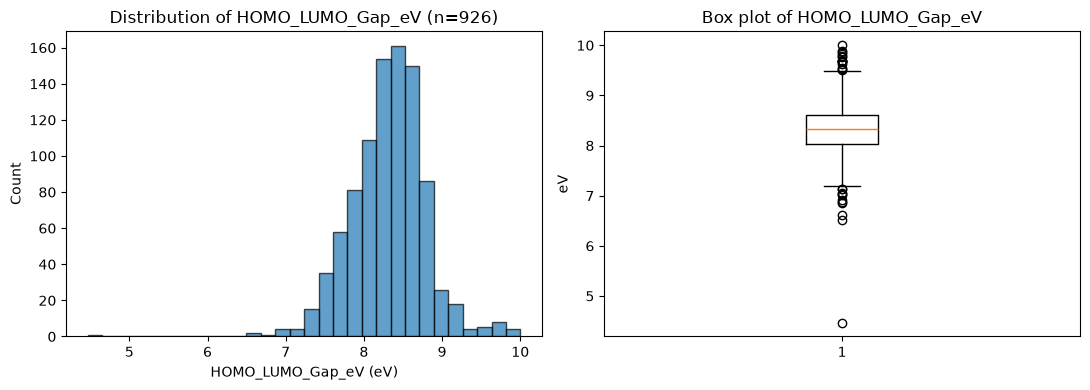

In [10]:
# ============ 目标分布：直方图 + 箱线图 ============
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 直方图
axes[0].hist(valid[target], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title(f"Distribution of HOMO_LUMO_Gap_eV (n={len(valid)})")
axes[0].set_xlabel("HOMO_LUMO_Gap_eV (eV)")
axes[0].set_ylabel("Count")

# 箱线图
axes[1].boxplot(valid[target], vert=True)
axes[1].set_title("Box plot of HOMO_LUMO_Gap_eV")
axes[1].set_ylabel("eV")

plt.tight_layout()
plt.show()

### 6b. 预测变量 → 目标的相关系数（Pearson 和 Spearman）

- **Pearson**：捕捉**线性**关系
- **Spearman**：捕捉**单调**关系（线性或非线性但持续同向）
- 两者差别大，说明关系不是简单线性

In [11]:
# ============ 相关系数（在有效建模行上）============
# 合并特征 + 目标
audit = valid[honest_feats + [target]]

pearson_corr = audit.corr(method="pearson")[target].sort_values(ascending=False)
spearman_corr = audit.corr(method="spearman")[target].sort_values(ascending=False)

print("=== 与带隙的 Pearson 相关（降序）===")
print(pearson_corr.round(3))
print("\n=== 与带隙的 Spearman 相关（降序）===")
print(spearman_corr.round(3))

print("\n=== Pearson vs Spearman 差异（可发现非线性关系）===")
diff = (pearson_corr - spearman_corr).abs().sort_values(ascending=False)
print(diff.round(3))

=== 与带隙的 Pearson 相关（降序）===
HOMO_LUMO_Gap_eV                                  1.000
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.078
Entropy_Hatree                                    0.034
Gibbs_Free_Energy_Hatree                          0.013
Energy_Hatree                                     0.013
Enthalpy_Hatree                                   0.013
Inner_energy_correction_Hatree                   -0.000
Dipole_Debye                                     -0.052
es                                               -0.131
Isotropic_Polarizability_au                      -0.228
Thermal_correction_to_Enthalpy_Hatree               NaN
Name: HOMO_LUMO_Gap_eV, dtype: float64

=== 与带隙的 Spearman 相关（降序）===
HOMO_LUMO_Gap_eV                                  1.000
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.081
Entropy_Hatree                                    0.064
Inner_energy_correction_Hatree                    0.053
Enthalpy_Hatree                                  -0.009
Gibbs_Fre

### 相关分析理解

> **哪些特征与带隙相关最强？** 从相关系数看（绝对值）：
> - `Isotropic_Polarizability_au` 与带隙的 Pearson 相关为 **-0.228**（最强）
> - `es` 为 **-0.131**
> - `Dipole_Debye` 为 **-0.052**
> - 其余特征相关性都很弱（|r| < 0.08）
> - 注意：`Thermal_correction_to_Enthalpy_Hatree` 在全部 926 个有效行上是**恒定值**（std=0），相关系数为 **NaN** → 这是**常量列，对预测毫无信息**，属于数据审计的一个发现。
>
> **有没有特征在 Pearson 和 Spearman 上差别很大？这说明什么？** 对比两表：**没有哪个特征的 Pearson 和 Spearman 差别很大**——最大差异也只有约 0.05（`Inner_energy_correction_Hatree` 为 0.054，`Entropy_Hatree` 为 0.031），其余都小于 0.023。这说明这些特征与带隙之间**没有显示出"强非线性但单调"的关系**。
>
> 更重要的是：**最强的相关也只有约 |0.21|**。所有诚实特征与带隙的关系都很弱，这**解释了为什么诚实线性回归的 test R² 只有 0.25**——特征与目标本身的联系不强，或者真实预测信号不在这 10 个"计算属性"里（带隙更可能依赖分子结构，这需要在后续用结构特征或神经网络来进一步探索）。